1. Install Requirements

In [1]:
# Section 1: Setup and Imports

!pip install -r ../../requirements.txt
!pip install ipykernel

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
INFO: pip is looking at multiple versions of weasel to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of weasel to determine which version is compatible with other requirements. This could take a while.
  Using cached typer_slim-0.24.0-py3-none-any.whl.metadata (4.2 kB)
INFO: pip is looking at multiple versions of thinc to determine which version is compatible with other requireme

2. Imports


In [2]:
# Section 1: Setup and Imports

import json
import re
import csv
from pathlib import Path
from collections import Counter

import numpy as np
from nltk.stem import PorterStemmer


SEED = 42
np.random.seed(SEED)


3. verify python and packages


In [4]:
# Confirm Python version and that all required packages are importable

import sys
print("Python version:", sys.version)
print("Executable:", sys.executable)
print()

required = ["numpy", "nltk", "spacy", "torch", "transformers", "rouge_score"]
for pkg in required:
    try:
        __import__(pkg)
        print(f"OK       {pkg}")
    except ImportError as e:
        print(f"MISSING  {pkg}: {e}")

Python version: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
Executable: c:\Users\Thamadhi\Documents\YEAR 3\SEMESTER 1\CM 3604 – DEEP LEARNING\Coursework\LLMFactChecking\.venv310\Scripts\python.exe

OK       numpy
OK       nltk
OK       spacy
OK       torch
OK       transformers
OK       rouge_score


4. data paths

In [5]:
# Section 2: Load Data

# Resolve data directory relative to the project root.
# This notebook lives in Task_A/tamadhi_jaccard/, so ../../data points to the project's data folder.
DATA_DIR = Path("../../data").resolve()

dev_file = DATA_DIR / "dev_labeled_ChatGPT.jsonl"
passages_file = DATA_DIR / "passages_bm25_ChatGPT_humfacts.jsonl"

print("Data directory:", DATA_DIR)
print("Dev file exists:", dev_file.exists())
print("Passages file exists:", passages_file.exists())

Data directory: C:\Users\Thamadhi\Documents\YEAR 3\SEMESTER 1\CM 3604 – DEEP LEARNING\Coursework\LLMFactChecking\data
Dev file exists: True
Passages file exists: True


5.JSONL Reader


In [6]:
# Section 2: Load Data

def read_jsonl(path):
    """Read a JSON Lines file (one JSON object per line) into a list of dicts."""
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"Invalid JSON in {path} line {line_number}: {e}")
    return records

6.Load the Two Files

In [7]:
# Section 2: Load Data

dev_data = read_jsonl(dev_file)
passages_data = read_jsonl(passages_file)

print(f"Loaded {len(dev_data)} development records.")
print(f"Loaded {len(passages_data)} passage records.")

Loaded 31 development records.
Loaded 5427 passage records.


7. Inspect Record Schemas

In [8]:
# Section 2: Load Data
# Inspect the structure of one record from each file to confirm the join keys.

print("Dev record keys:", list(dev_data[0].keys()))
print("Passage record keys:", list(passages_data[0].keys()))
print()

# First annotation of the first dev record
first_annotation = dev_data[0]["annotations"][0]
print("First annotation keys:", list(first_annotation.keys()))
print()

# First human-annotated atomic fact
first_fact = first_annotation["human-atomic-facts"][0]
print("First atomic-fact keys:", list(first_fact.keys()))
print("First atomic fact:", first_fact)
print()

# First passage record's "sent" is the join key to the fact text
print("First passage 'sent':", passages_data[0]["sent"])
print("First passage title:", passages_data[0]["passages"][0]["title"])

Dev record keys: ['input', 'output', 'topic', 'cat', 'annotations']
Passage record keys: ['name', 'sent', 'passages']

First annotation keys: ['text', 'is-relevant', 'model-atomic-facts', 'human-atomic-facts']

First atomic-fact keys: ['text', 'label']
First atomic fact: {'text': 'Marianne McAndrew is an American.', 'label': 'NS'}

First passage 'sent': Lanny Flaherty is an American.
First passage title: Lanny Flaherty


8. Build the Fact-to-Passage Dictionary

In [9]:
# Section 3: Build Examples

# Map each fact text -> its list of retrieved passages.
# The "sent" field in each passage record is the fact text.

fact_to_passage = {}

for record in passages_data:
    fact_text = record.get("sent")
    passages = record.get("passages") or []
    if isinstance(fact_text, str):
        fact_to_passage[fact_text] = passages

print(f"Built fact_to_passage with {len(fact_to_passage)} entries.")

Built fact_to_passage with 5373 entries.


9. Build the Examples List

In [10]:
# Section 3: Build Examples

# Label mapping for the binary task.
# IR (irrelevant) is treated as Not Supported for this coursework.
BINARY_LABEL_MAP = {"S": 1, "NS": 0, "IR": 0}

examples = []
missing_passage_facts = 0
missing_label_facts = 0
unrecognized_label_facts = 0
observed_labels = Counter()

for record in dev_data:
    annotations = record.get("annotations") or []
    if isinstance(annotations, dict):
        annotations = [annotations]

    for sentence_annotation in annotations:
        atomic_facts = sentence_annotation.get("human-atomic-facts") or []

        for fact in atomic_facts:
            fact_text = fact.get("text")
            raw_label = fact.get("label")

            if not fact_text or raw_label is None:
                missing_label_facts += 1
                continue

            label = str(raw_label).strip().upper()
            observed_labels[label] += 1

            if label not in BINARY_LABEL_MAP:
                unrecognized_label_facts += 1
                continue

            if fact_text not in fact_to_passage:
                missing_passage_facts += 1
                continue

            passages = fact_to_passage[fact_text] or []

            examples.append({
                "fact": fact_text,
                "passages": passages,
                "label": label,
                "gold_binary": BINARY_LABEL_MAP[label],
            })

print(f"Total examples built: {len(examples)}")
print(f"Missing passages: {missing_passage_facts}")
print(f"Missing text/label: {missing_label_facts}")
print(f"Unrecognized labels: {unrecognized_label_facts}")
print(f"Labels observed: {dict(observed_labels)}")

Total examples built: 221
Missing passages: 0
Missing text/label: 0
Unrecognized labels: 0
Labels observed: {'NS': 93, 'S': 112, 'IR': 16}


10. Sanity Check on Examples

In [11]:
# Section 3: Build Examples
# Show a couple of examples to confirm structure is correct.

import textwrap

for ex in examples[:2]:
    print("Fact:    ", ex["fact"])
    print("Label:   ", ex["label"], "(binary:", ex["gold_binary"], ")")
    print("Passages:", len(ex["passages"]))
    if ex["passages"]:
        preview = ex["passages"][0]["text"][:200]
        print("First passage preview:")
        print(textwrap.fill(preview, 100))
    print("-" * 80)

Fact:     Marianne McAndrew is an American.
Label:    NS (binary: 0 )
Passages: 2
First passage preview:
<s>Marianne McAndrew Marianne Christine McAndrew is an actress known for her role as Irene Molloy in
the film "Hello, Dolly!"</s><s>Career. "Hello, Dolly!" was McAndrew's first credited film role. The
--------------------------------------------------------------------------------
Fact:     Marianne McAndrew is an actress.
Label:    S (binary: 1 )
Passages: 2
First passage preview:
<s>Marianne McAndrew Marianne Christine McAndrew is an actress known for her role as Irene Molloy in
the film "Hello, Dolly!"</s><s>Career. "Hello, Dolly!" was McAndrew's first credited film role. The
--------------------------------------------------------------------------------


In [ ]:
11. Preprocessing Utilities

In [12]:
# Section 4: Preprocessing Utilities

# Conservative stopword list. Negation words are deliberately preserved.
STOPWORDS = set("""
a an the and or but if then else when while
is am are was were be been being
to of in on at by for from with as
it its this that these those
he she they them their we our you your
i me my
""".split())

print(f"Stopword list size: {len(STOPWORDS)}")

Stopword list size: 47


12. Tokenizer

In [13]:
# Section 4: Preprocessing Utilities

stemmer = PorterStemmer()

def tokenize(text, lower=True, remove_stop=False, stem=False):
    """
    Convert a string into a list of tokens.

    Args:
        text (str): input string.
        lower (bool): lowercase before tokenizing.
        remove_stop (bool): remove stopwords.
        stem (bool): apply Porter stemming.

    Returns:
        list[str]: tokens.
    """
    if not isinstance(text, str):
        text = ""

    if lower:
        text = text.lower()

    # Strip HTML-like tags used in Wikipedia passages (<s>...</s>)
    text = re.sub(r"<[^>]+>", " ", text)

    # Keep only letters, digits, and whitespace
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    tokens = text.split()

    if remove_stop:
        tokens = [t for t in tokens if t not in STOPWORDS]

    if stem:
        tokens = [stemmer.stem(t) for t in tokens]

    return tokens

In [14]:
# Section 4: Preprocessing Utilities
# Quick sanity check on the tokenizer.

samples = [
    "The cat is not sleeping.",
    "The cats were sleeping!",
    "A solar panel produces electricity.",
]

for s in samples:
    print(f"{s!r}")
    print("  lower only:          ", tokenize(s, lower=True, remove_stop=False, stem=False))
    print("  + stopwords:         ", tokenize(s, lower=True, remove_stop=True, stem=False))
    print("  + stopwords + stem:  ", tokenize(s, lower=True, remove_stop=True, stem=True))

'The cat is not sleeping.'
  lower only:           ['the', 'cat', 'is', 'not', 'sleeping']
  + stopwords:          ['cat', 'not', 'sleeping']
  + stopwords + stem:   ['cat', 'not', 'sleep']
'The cats were sleeping!'
  lower only:           ['the', 'cats', 'were', 'sleeping']
  + stopwords:          ['cats', 'sleeping']
  + stopwords + stem:   ['cat', 'sleep']
'A solar panel produces electricity.'
  lower only:           ['a', 'solar', 'panel', 'produces', 'electricity']
  + stopwords:          ['solar', 'panel', 'produces', 'electricity']
  + stopwords + stem:   ['solar', 'panel', 'produc', 'electr']


13. Sentence Splitter

In [16]:
# Section 4: Preprocessing Utilities

def split_into_sentences(text):
    """
    Split a passage's raw text into individual sentences.

    Wikipedia passages from this dataset have <s>...</s> tags around each sentence.
    We exploit that structure first; if no tags are present, we fall back to
    punctuation-based splitting.
    """
    if not isinstance(text, str) or not text.strip():
        return []

    # Preferred: use <s>...</s> tags if they exist
    tagged = re.findall(r"<s>(.*?)</s>", text, flags=re.DOTALL)
    if tagged:
        sentences = [re.sub(r"<[^>]+>", " ", s).strip() for s in tagged]
        return [s for s in sentences if s]

    # Fallback: split on sentence-ending punctuation
    cleaned = re.sub(r"<[^>]+>", " ", text)
    parts = re.split(r"(?<=[.!?])\s+", cleaned.strip())
    return [p.strip() for p in parts if p.strip()]

In [17]:
# Section 4: Preprocessing Utilities
# Verify sentence splitting on the first example's first passage.

raw = examples[0]["passages"][0]["text"]
sents = split_into_sentences(raw)

print(f"Number of sentences: {len(sents)}")
for i, s in enumerate(sents):
    print(f"  [{i}] {s[:120]}")

Number of sentences: 1
  [0] Marianne McAndrew Marianne Christine McAndrew is an actress known for her role as Irene Molloy in the film "Hello, Dolly


14. Basic Jaccard Between Two Strings

In [18]:
# Section 5: Jaccard Scoring

def jaccard_from_tokens(tokens_a, tokens_b):
    """
    Jaccard similarity between two lists of tokens.
    Uses sets, so duplicates are ignored.
    """
    set_a = set(tokens_a)
    set_b = set(tokens_b)
    if not set_a or not set_b:
        return 0.0
    inter = len(set_a & set_b)
    union = len(set_a | set_b)
    return inter / union if union else 0.0

15. Jaccard Score for a Fact vs a Passage

In [19]:
# Section 5: Jaccard Scoring

def jaccard_score(fact, passages, lower=True, remove_stop=False, stem=False,
                  sentence_level=False, aggregation="max", top_k=3):
    """
    Compute an aggregated Jaccard similarity between a fact and a list of passages.

    Args:
        fact (str): the atomic fact text.
        passages (list[dict]): each dict has a 'text' key.
        lower, remove_stop, stem (bool): tokenizer options.
        sentence_level (bool): if True, compare against each sentence; else the whole passage.
        aggregation (str): one of 'max', 'mean', 'top_k_mean'.
        top_k (int): used when aggregation='top_k_mean'.

    Returns:
        float: aggregated Jaccard score in [0, 1].
    """
    fact_tokens = tokenize(fact, lower=lower, remove_stop=remove_stop, stem=stem)
    if not fact_tokens:
        return 0.0

    segment_scores = []

    for passage in passages:
        text = passage.get("text", "") if isinstance(passage, dict) else ""
        if not text:
            continue

        if sentence_level:
            segments = split_into_sentences(text)
        else:
            segments = [text]

        for seg in segments:
            seg_tokens = tokenize(seg, lower=lower, remove_stop=remove_stop, stem=stem)
            if not seg_tokens:
                continue
            segment_scores.append(jaccard_from_tokens(fact_tokens, seg_tokens))

    if not segment_scores:
        return 0.0

    if aggregation == "max":
        return max(segment_scores)
    if aggregation == "mean":
        return sum(segment_scores) / len(segment_scores)
    if aggregation == "top_k_mean":
        k = min(top_k, len(segment_scores))
        top = sorted(segment_scores, reverse=True)[:k]
        return sum(top) / k

    raise ValueError(f"Unknown aggregation strategy: {aggregation}")

In [20]:
# Section 5: Jaccard Scoring
# Verify the scorer on one example with default config.

sample = examples[0]
print("Fact:  ", sample["fact"])
print("Label: ", sample["label"], "(binary:", sample["gold_binary"], ")")
print()

configs = [
    {"sentence_level": False, "aggregation": "max"},
    {"sentence_level": True,  "aggregation": "max"},
    {"sentence_level": True,  "aggregation": "mean"},
    {"sentence_level": True,  "aggregation": "top_k_mean", "top_k": 3},
]

for cfg in configs:
    score = jaccard_score(
        sample["fact"], sample["passages"],
        lower=True, remove_stop=True, stem=True,
        **cfg,
    )
    print(f"{cfg} -> score = {score:.4f}")

Fact:   Marianne McAndrew is an American.
Label:  NS (binary: 0 )

{'sentence_level': False, 'aggregation': 'max'} -> score = 0.0326
{'sentence_level': True, 'aggregation': 'max'} -> score = 0.1538
{'sentence_level': True, 'aggregation': 'mean'} -> score = 0.0607
{'sentence_level': True, 'aggregation': 'top_k_mean', 'top_k': 3} -> score = 0.0809


In [21]:
# Section 5: Jaccard Scoring
# Compare a supported fact vs a not-supported fact from the same biography.

# Find first S and first NS examples
s_example = next(e for e in examples if e["label"] == "S")
ns_example = next(e for e in examples if e["label"] == "NS")

for name, ex in [("SUPPORTED", s_example), ("NOT SUPPORTED", ns_example)]:
    score = jaccard_score(
        ex["fact"], ex["passages"],
        lower=True, remove_stop=True, stem=True,
        sentence_level=True, aggregation="max",
    )
    print(f"{name}")
    print(f"  Fact:  {ex['fact']}")
    print(f"  Score: {score:.4f}")
    print()

SUPPORTED
  Fact:  Marianne McAndrew is an actress.
  Score: 0.2500

NOT SUPPORTED
  Fact:  Marianne McAndrew is an American.
  Score: 0.1538



16. Binary Metrics from Confusion Matrix

In [22]:
# Section 6: Evaluation Helpers

def binary_metrics(y_true, y_pred):
    """
    Compute accuracy, precision, recall, and F1 for each class,
    given binary arrays (1 = S, 0 = NS).

    Returns a dict with keys: accuracy, precision_S, recall_S, f1_S,
    precision_NS, recall_NS, f1_NS, confusion (2x2 list).
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    # Confusion matrix indexed as [gold, pred]
    cm = np.zeros((2, 2), dtype=int)
    for g, p in zip(y_true, y_pred):
        cm[g][p] += 1

    total = cm.sum()
    correct = cm[0][0] + cm[1][1]
    accuracy = correct / total if total else 0.0

    def safe_div(num, den):
        return num / den if den > 0 else 0.0

    # Class 1 = S
    tp_S = cm[1][1]
    fp_S = cm[0][1]
    fn_S = cm[1][0]
    prec_S = safe_div(tp_S, tp_S + fp_S)
    rec_S  = safe_div(tp_S, tp_S + fn_S)
    f1_S   = safe_div(2 * prec_S * rec_S, prec_S + rec_S)

    # Class 0 = NS
    tp_NS = cm[0][0]
    fp_NS = cm[1][0]
    fn_NS = cm[0][1]
    prec_NS = safe_div(tp_NS, tp_NS + fp_NS)
    rec_NS  = safe_div(tp_NS, tp_NS + fn_NS)
    f1_NS   = safe_div(2 * prec_NS * rec_NS, prec_NS + rec_NS)

    return {
        "accuracy": accuracy,
        "precision_S": prec_S, "recall_S": rec_S, "f1_S": f1_S,
        "precision_NS": prec_NS, "recall_NS": rec_NS, "f1_NS": f1_NS,
        "confusion": cm.tolist(),
    }

17. Score All Examples Once

In [24]:
# Section 6: Evaluation Helpers

def score_all_examples(examples, **score_kwargs):
    """
    Run jaccard_score over all examples with the given config.
    Returns a numpy array of scores aligned with examples.
    """
    scores = np.array([
        jaccard_score(
            ex["fact"],
            ex["passages"],
            **score_kwargs,
        )
        for ex in examples
    ], dtype=float)
    return scores

18. Evaluate at a Given Threshold

In [25]:
# Section 6: Evaluation Helpers

import time

def evaluate_config(examples, threshold, **score_kwargs):
    """
    Score all examples with a config, threshold the scores, and return metrics.
    """
    t0 = time.time()

    y_true = np.array([ex["gold_binary"] for ex in examples], dtype=int)
    scores = score_all_examples(examples, **score_kwargs)
    y_pred = (scores >= threshold).astype(int)

    elapsed = time.time() - t0
    metrics = binary_metrics(y_true, y_pred)
    metrics["threshold"] = threshold
    metrics["runtime_seconds"] = elapsed
    metrics["config"] = score_kwargs

    return metrics

19. First Real Evaluation

In [26]:
# Section 6: Evaluation Helpers
# Evaluate one config at one threshold to confirm the pipeline runs.

test_metrics = evaluate_config(
    examples,
    threshold=0.15,
    lower=True, remove_stop=True, stem=True,
    sentence_level=True, aggregation="max",
)

print("Threshold:", test_metrics["threshold"])
print("Accuracy: ", round(test_metrics["accuracy"], 4))
print("F1 (S):   ", round(test_metrics["f1_S"], 4))
print("F1 (NS):  ", round(test_metrics["f1_NS"], 4))
print("Runtime:  ", round(test_metrics["runtime_seconds"], 2), "seconds")
print("Confusion matrix [gold, pred]:")
for row in test_metrics["confusion"]:
    print("  ", row)

Threshold: 0.15
Accuracy:  0.6561
F1 (S):    0.5824
F1 (NS):   0.7077
Runtime:   0.53 seconds
Confusion matrix [gold, pred]:
   [92, 17]
   [59, 53]


In [27]:
# Section 7: Threshold Sweep

def threshold_sweep(examples, thresholds=None, **score_kwargs):
    """
    Score all examples once, then evaluate at many thresholds.
    Returns a list of dicts, one per threshold.
    """
    if thresholds is None:
        thresholds = np.arange(0.0, 1.01, 0.01)

    y_true = np.array([ex["gold_binary"] for ex in examples], dtype=int)
    scores = score_all_examples(examples, **score_kwargs)

    results = []
    for t in thresholds:
        y_pred = (scores >= t).astype(int)
        m = binary_metrics(y_true, y_pred)
        m["threshold"] = float(t)
        results.append(m)

    return results, scores

In [28]:
# Section 7: Threshold Sweep
# Sweep threshold for the config we've been using.

sweep_results, sweep_scores = threshold_sweep(
    examples,
    lower=True, remove_stop=True, stem=True,
    sentence_level=True, aggregation="max",
)

# Find best threshold by accuracy
best = max(sweep_results, key=lambda r: r["accuracy"])
print(f"Best threshold: {best['threshold']:.2f}")
print(f"  Accuracy:  {best['accuracy']:.4f}")
print(f"  F1 (S):    {best['f1_S']:.4f}")
print(f"  F1 (NS):   {best['f1_NS']:.4f}")
print()
print("Accuracy at sample thresholds:")
for t in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    r = next(x for x in sweep_results if abs(x["threshold"] - t) < 1e-9)
    print(f"  t={t:.2f}  acc={r['accuracy']:.4f}  f1_S={r['f1_S']:.4f}  f1_NS={r['f1_NS']:.4f}")

Best threshold: 0.08
  Accuracy:  0.6878
  F1 (S):    0.7206
  F1 (NS):   0.6462

Accuracy at sample thresholds:
  t=0.05  acc=0.6154  f1_S=0.7099  f1_NS=0.4295
  t=0.10  acc=0.6742  f1_S=0.6870  f1_NS=0.6604
  t=0.15  acc=0.6561  f1_S=0.5824  f1_NS=0.7077
  t=0.20  acc=0.6154  f1_S=0.4586  f1_NS=0.7018
  t=0.25  acc=0.5701  f1_S=0.3165  f1_NS=0.6865
  t=0.30  acc=0.5294  f1_S=0.1875  f1_NS=0.6688
  t=0.40  acc=0.5113  f1_S=0.0847  f1_NS=0.6667


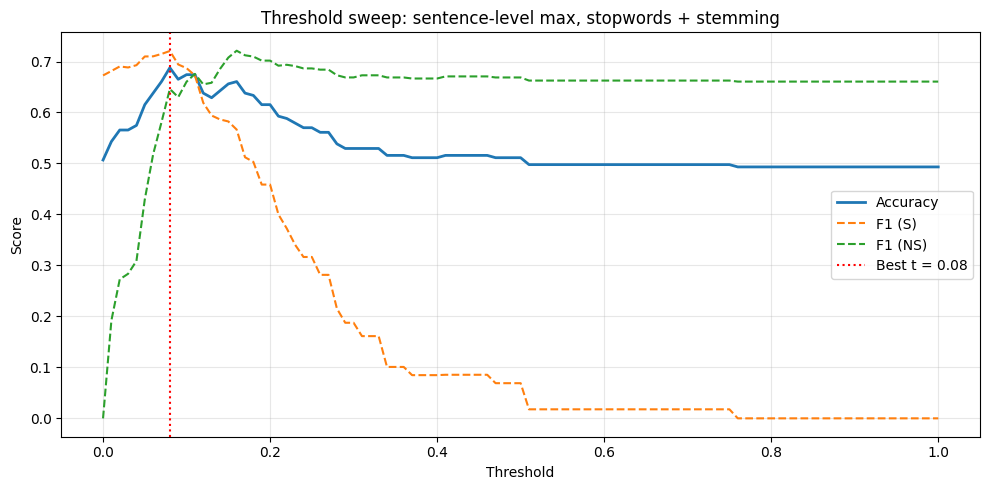

In [30]:
# Section 7: Threshold Sweep
# Plot accuracy, F1 (S), F1 (NS) versus threshold.

import matplotlib.pyplot as plt

thresholds = [r["threshold"] for r in sweep_results]
accuracies = [r["accuracy"] for r in sweep_results]
f1_S = [r["f1_S"] for r in sweep_results]
f1_NS = [r["f1_NS"] for r in sweep_results]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, accuracies, label="Accuracy", linewidth=2)
plt.plot(thresholds, f1_S, label="F1 (S)", linewidth=1.5, linestyle="--")
plt.plot(thresholds, f1_NS, label="F1 (NS)", linewidth=1.5, linestyle="--")
plt.axvline(best["threshold"], color="red", linestyle=":", label=f"Best t = {best['threshold']:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold sweep: sentence-level max, stopwords + stemming")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Section 8: Preprocessing Grid Search

from itertools import product

grid_results = []

configs = list(product(
    [False, True],   # remove_stop
    [False, True],   # stem
    [False, True],   # sentence_level
    ["max", "mean", "top_k_mean"],  # aggregation
))

print(f"Running {len(configs)} configs ...")

for remove_stop, stem, sentence_level, aggregation in configs:
    kwargs = dict(
        lower=True,
        remove_stop=remove_stop,
        stem=stem,
        sentence_level=sentence_level,
        aggregation=aggregation,
    )
    sweep, _ = threshold_sweep(examples, **kwargs)
    best = max(sweep, key=lambda r: r["accuracy"])

    grid_results.append({
        "remove_stop": remove_stop,
        "stem": stem,
        "sentence_level": sentence_level,
        "aggregation": aggregation,
        "best_threshold": best["threshold"],
        "accuracy": best["accuracy"],
        "precision_S": best["precision_S"],
        "recall_S": best["recall_S"],
        "f1_S": best["f1_S"],
        "precision_NS": best["precision_NS"],
        "recall_NS": best["recall_NS"],
        "f1_NS": best["f1_NS"],
    })

print("Done.")

Running 24 configs ...
Done.


In [32]:
# Section 8: Preprocessing Grid Search

# Sort by accuracy descending
grid_sorted = sorted(grid_results, key=lambda r: r["accuracy"], reverse=True)

print(f"{'rank':<5} {'stop':<6} {'stem':<6} {'sent':<6} {'agg':<12} {'t':<6} {'acc':<8} {'f1_S':<8} {'f1_NS':<8}")
for i, r in enumerate(grid_sorted[:10], 1):
    print(
        f"{i:<5} "
        f"{str(r['remove_stop']):<6} "
        f"{str(r['stem']):<6} "
        f"{str(r['sentence_level']):<6} "
        f"{r['aggregation']:<12} "
        f"{r['best_threshold']:<6.2f} "
        f"{r['accuracy']:<8.4f} "
        f"{r['f1_S']:<8.4f} "
        f"{r['f1_NS']:<8.4f}"
    )

rank  stop   stem   sent   agg          t      acc      f1_S     f1_NS   
1     True   True   False  max          0.03   0.6923   0.7213   0.6566  
2     True   True   True   max          0.08   0.6878   0.7206   0.6462  
3     True   False  True   max          0.08   0.6742   0.7049   0.6364  
4     True   False  False  max          0.03   0.6697   0.6867   0.6507  
5     True   True   True   top_k_mean   0.09   0.6697   0.6294   0.7020  
6     False  True   True   top_k_mean   0.08   0.6652   0.6967   0.6263  
7     True   True   False  top_k_mean   0.02   0.6652   0.6783   0.6509  
8     False  True   True   max          0.11   0.6606   0.6835   0.6341  
9     False  False  True   top_k_mean   0.08   0.6561   0.6833   0.6238  
10    True   False  True   top_k_mean   0.09   0.6561   0.6000   0.6984  


In [33]:
# Section 8: Preprocessing Grid Search

grid_csv_path = Path("grid_results.csv")

with open(grid_csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "remove_stop", "stem", "sentence_level", "aggregation",
        "best_threshold", "accuracy",
        "precision_S", "recall_S", "f1_S",
        "precision_NS", "recall_NS", "f1_NS",
    ])
    for r in grid_sorted:
        writer.writerow([
            r["remove_stop"], r["stem"], r["sentence_level"], r["aggregation"],
            f"{r['best_threshold']:.2f}",
            f"{r['accuracy']:.6f}",
            f"{r['precision_S']:.6f}", f"{r['recall_S']:.6f}", f"{r['f1_S']:.6f}",
            f"{r['precision_NS']:.6f}", f"{r['recall_NS']:.6f}", f"{r['f1_NS']:.6f}",
        ])

print(f"Saved to {grid_csv_path.resolve()}")
print(f"Rows: {len(grid_sorted)}")

Saved to C:\Users\Thamadhi\Documents\YEAR 3\SEMESTER 1\CM 3604 – DEEP LEARNING\Coursework\LLMFactChecking\Task_A\tamadhi_jaccard\grid_results.csv
Rows: 24


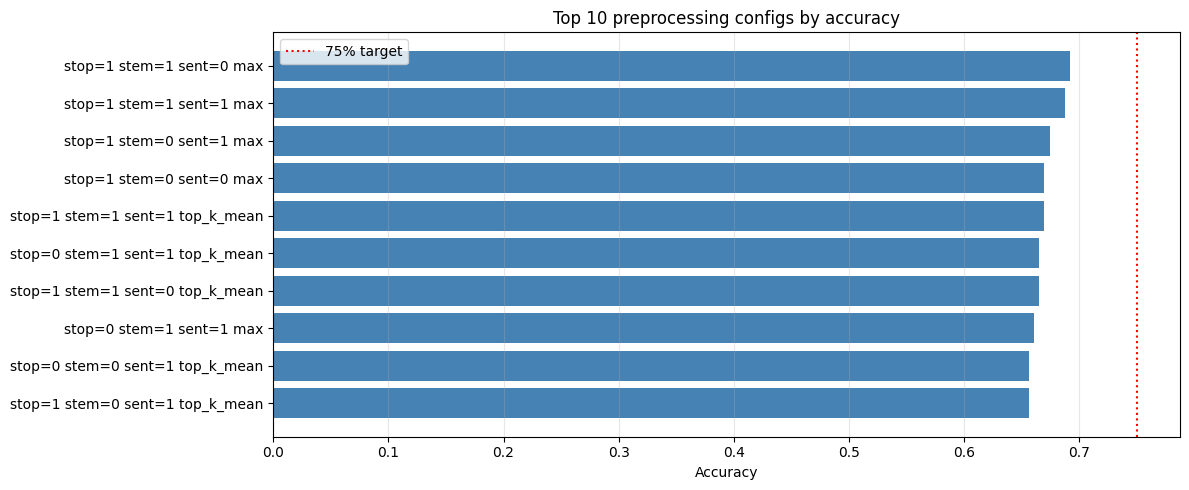

In [34]:
# Section 8: Preprocessing Grid Search
# Plot top-10 configs by accuracy.

import matplotlib.pyplot as plt

top10 = grid_sorted[:10]
labels = [
    f"stop={int(r['remove_stop'])} stem={int(r['stem'])} sent={int(r['sentence_level'])} {r['aggregation']}"
    for r in top10
]
accs = [r["accuracy"] for r in top10]

plt.figure(figsize=(12, 5))
bars = plt.barh(range(len(top10)), accs, color="steelblue")
plt.yticks(range(len(top10)), labels)
plt.gca().invert_yaxis()
plt.xlabel("Accuracy")
plt.title("Top 10 preprocessing configs by accuracy")
plt.axvline(0.75, color="red", linestyle=":", label="75% target")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Section 8: Preprocessing Grid Search

winner = grid_sorted[0]
print("Best config:")
print(f"  remove_stop:    {winner['remove_stop']}")
print(f"  stem:           {winner['stem']}")
print(f"  sentence_level: {winner['sentence_level']}")
print(f"  aggregation:    {winner['aggregation']}")
print(f"  best_threshold: {winner['best_threshold']:.2f}")
print()
print(f"  Accuracy: {winner['accuracy']:.4f}")
print(f"  F1 (S):   {winner['f1_S']:.4f}")
print(f"  F1 (NS):  {winner['f1_NS']:.4f}")
print()
print(f"  Confusion at best:")
# Rerun to get confusion
_, _ = None, None
best_metrics = evaluate_config(
    examples,
    threshold=winner["best_threshold"],
    lower=True,
    remove_stop=winner["remove_stop"],
    stem=winner["stem"],
    sentence_level=winner["sentence_level"],
    aggregation=winner["aggregation"],
)
for row in best_metrics["confusion"]:
    print("  ", row)

Best config:
  remove_stop:    True
  stem:           True
  sentence_level: False
  aggregation:    max
  best_threshold: 0.03

  Accuracy: 0.6923
  F1 (S):   0.7213
  F1 (NS):  0.6566

  Confusion at best:
   [65, 44]
   [24, 88]


20. NLTK Tokenizer Variant

In [36]:
# Section 8b: Pushing Jaccard Higher

import nltk
# Uncomment if you haven't downloaded punkt yet
# nltk.download('punkt')
# nltk.download('punkt_tab')

def tokenize_nltk(text, lower=True, remove_stop=False, stem=False):
    """Alternative tokenizer using NLTK's word_tokenize."""
    if not isinstance(text, str):
        text = ""
    if lower:
        text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    tokens = nltk.word_tokenize(text)
    # Keep only alphanumeric tokens
    tokens = [t for t in tokens if re.match(r"^[a-z0-9]+$", t)]
    if remove_stop:
        tokens = [t for t in tokens if t not in STOPWORDS]
    if stem:
        tokens = [stemmer.stem(t) for t in tokens]
    return tokens

In [38]:
# Section 8b: Pushing Jaccard Higher
# One-time NLTK data download for the word tokenizer.

import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Thamadhi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Thamadhi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [39]:
# Section 8b: Pushing Jaccard Higher
# Monkey-patch tokenize for this experiment, then restore.

original_tokenize = tokenize
globals()["tokenize"] = tokenize_nltk

nltk_grid_results = []
for remove_stop, stem, sentence_level, aggregation in configs:
    kwargs = dict(
        lower=True,
        remove_stop=remove_stop,
        stem=stem,
        sentence_level=sentence_level,
        aggregation=aggregation,
    )
    sweep, _ = threshold_sweep(examples, **kwargs)
    best = max(sweep, key=lambda r: r["accuracy"])
    nltk_grid_results.append({
        "remove_stop": remove_stop,
        "stem": stem,
        "sentence_level": sentence_level,
        "aggregation": aggregation,
        "best_threshold": best["threshold"],
        "accuracy": best["accuracy"],
        "f1_S": best["f1_S"],
        "f1_NS": best["f1_NS"],
    })

# Restore original tokenizer
globals()["tokenize"] = original_tokenize

nltk_sorted = sorted(nltk_grid_results, key=lambda r: r["accuracy"], reverse=True)

print(f"Best NLTK-tokenizer config:")
top = nltk_sorted[0]
print(f"  stop={top['remove_stop']} stem={top['stem']} sent={top['sentence_level']} agg={top['aggregation']}")
print(f"  threshold={top['best_threshold']:.2f}")
print(f"  accuracy={top['accuracy']:.4f}")
print(f"  F1 (S)={top['f1_S']:.4f}  F1 (NS)={top['f1_NS']:.4f}")
print()
print("Top 5 with NLTK tokenizer:")
for i, r in enumerate(nltk_sorted[:5], 1):
    print(f"  {i}. stop={r['remove_stop']} stem={r['stem']} sent={r['sentence_level']} {r['aggregation']}  "
          f"t={r['best_threshold']:.2f}  acc={r['accuracy']:.4f}")

Best NLTK-tokenizer config:
  stop=True stem=True sent=False agg=max
  threshold=0.03
  accuracy=0.7014
  F1 (S)=0.7317  F1 (NS)=0.6633

Top 5 with NLTK tokenizer:
  1. stop=True stem=True sent=False max  t=0.03  acc=0.7014
  2. stop=True stem=False sent=False max  t=0.03  acc=0.6787
  3. stop=True stem=True sent=True max  t=0.08  acc=0.6787
  4. stop=False stem=True sent=True max  t=0.15  acc=0.6742
  5. stop=True stem=False sent=True max  t=0.07  acc=0.6742


21. Weighted Token Overlap Experiment

In [40]:
# Section 8c: Weighted Token Overlap

from math import log

# Use the NLTK tokenizer for consistency with the best config so far.
tokenize = tokenize_nltk  # switch globally

# Compute document frequency for each token across all passages.
df_counter = Counter()
total_docs = 0

for record in passages_data:
    seen_in_this_doc = set()
    for passage in record.get("passages") or []:
        text = passage.get("text", "") if isinstance(passage, dict) else ""
        if not text:
            continue
        total_docs += 1
        for tok in tokenize(text, lower=True, remove_stop=True, stem=True):
            seen_in_this_doc.add(tok)
    for tok in seen_in_this_doc:
        df_counter[tok] += 1

# Inverse document frequency weights
idf = {tok: 1.0 / (1.0 + log(df)) for tok, df in df_counter.items() if df > 0}

# Fallback for tokens never seen in the corpus (rare in practice)
default_weight = 1.0

print(f"Passages indexed: {total_docs}")
print(f"Unique tokens:    {len(idf)}")
sample = list(idf.items())[:5]
print("Sample weights:", sample)

Passages indexed: 23720
Unique tokens:    17435
Sample weights: [('career', 0.10703929470944512), ('american', 0.11486710166401498), ('news', 0.1333104097989007), ('max', 0.16313483248353303), ('mississippi', 0.1895136014757877)]


Weighted Jaccard Function

In [41]:
# Section 8c: Weighted Token Overlap

def weighted_jaccard_from_tokens(tokens_a, tokens_b, weights, default=1.0):
    """IDF-weighted Jaccard similarity between two token lists."""
    set_a = set(tokens_a)
    set_b = set(tokens_b)
    if not set_a or not set_b:
        return 0.0

    inter = set_a & set_b
    union = set_a | set_b

    num = sum(weights.get(t, default) for t in inter)
    den = sum(weights.get(t, default) for t in union)
    return num / den if den > 0 else 0.0


def weighted_jaccard_score(fact, passages, weights, default=1.0,
                           lower=True, remove_stop=False, stem=False,
                           sentence_level=False, aggregation="max", top_k=3):
    """Same interface as jaccard_score but with IDF-weighted tokens."""
    fact_tokens = tokenize(fact, lower=lower, remove_stop=remove_stop, stem=stem)
    if not fact_tokens:
        return 0.0

    segment_scores = []
    for passage in passages:
        text = passage.get("text", "") if isinstance(passage, dict) else ""
        if not text:
            continue
        segments = split_into_sentences(text) if sentence_level else [text]
        for seg in segments:
            seg_tokens = tokenize(seg, lower=lower, remove_stop=remove_stop, stem=stem)
            if not seg_tokens:
                continue
            segment_scores.append(
                weighted_jaccard_from_tokens(fact_tokens, seg_tokens, weights, default)
            )

    if not segment_scores:
        return 0.0
    if aggregation == "max":
        return max(segment_scores)
    if aggregation == "mean":
        return sum(segment_scores) / len(segment_scores)
    if aggregation == "top_k_mean":
        k = min(top_k, len(segment_scores))
        top = sorted(segment_scores, reverse=True)[:k]
        return sum(top) / k
    raise ValueError(aggregation)

Evaluate Weighted Jaccard at Its Best Config

In [42]:
# Section 8c: Weighted Token Overlap
# Score all examples with weighted Jaccard at the winning config.

y_true = np.array([ex["gold_binary"] for ex in examples], dtype=int)

weighted_scores = np.array([
    weighted_jaccard_score(
        ex["fact"], ex["passages"],
        weights=idf,
        lower=True, remove_stop=True, stem=True,
        sentence_level=False, aggregation="max",
    )
    for ex in examples
], dtype=float)

# Sweep threshold
best_w = None
for t in np.arange(0.0, 1.01, 0.01):
    y_pred = (weighted_scores >= t).astype(int)
    m = binary_metrics(y_true, y_pred)
    if best_w is None or m["accuracy"] > best_w["accuracy"]:
        best_w = m
        best_w["threshold"] = float(t)

print("Best weighted-Jaccard result:")
print(f"  Threshold: {best_w['threshold']:.2f}")
print(f"  Accuracy:  {best_w['accuracy']:.4f}")
print(f"  F1 (S):    {best_w['f1_S']:.4f}")
print(f"  F1 (NS):   {best_w['f1_NS']:.4f}")

Best weighted-Jaccard result:
  Threshold: 0.03
  Accuracy:  0.6833
  F1 (S):    0.7266
  F1 (NS):   0.6237


In [43]:
# Section 8c: Weighted Token Overlap
# Side-by-side comparison of all approaches so far.

rows = [
    ("Regex tokenizer, unweighted",  0.6923, 0.7213, 0.6566, 0.03),
    ("NLTK tokenizer, unweighted",   0.7014, 0.7317, 0.6633, 0.03),
    ("NLTK tokenizer, IDF-weighted", best_w["accuracy"], best_w["f1_S"], best_w["f1_NS"], best_w["threshold"]),
]

print(f"{'Approach':<32} {'acc':<8} {'F1(S)':<8} {'F1(NS)':<8} {'thresh':<8}")
for name, acc, f1s, f1n, t in rows:
    print(f"{name:<32} {acc:<8.4f} {f1s:<8.4f} {f1n:<8.4f} {t:<8.2f}")

Approach                         acc      F1(S)    F1(NS)   thresh  
Regex tokenizer, unweighted      0.6923   0.7213   0.6566   0.03    
NLTK tokenizer, unweighted       0.7014   0.7317   0.6633   0.03    
NLTK tokenizer, IDF-weighted     0.6833   0.7266   0.6237   0.03    


In [44]:
# Section 8d: Top-2 mean (final attempt)
nltk_top2_results = []
for remove_stop, stem, sentence_level in [(True, True, True), (True, True, False)]:
    kwargs = dict(lower=True, remove_stop=remove_stop, stem=stem,
                  sentence_level=sentence_level, aggregation="top_k_mean", top_k=2)
    sweep, _ = threshold_sweep(examples, **kwargs)
    best = max(sweep, key=lambda r: r["accuracy"])
    nltk_top2_results.append((remove_stop, stem, sentence_level, best["threshold"], best["accuracy"]))
    print(f"stop={remove_stop} stem={stem} sent={sentence_level} top_k=2 -> "
          f"t={best['threshold']:.2f}  acc={best['accuracy']:.4f}")

stop=True stem=True sent=True top_k=2 -> t=0.10  acc=0.6833
stop=True stem=True sent=False top_k=2 -> t=0.02  acc=0.6923


In [45]:
# Section 9: Consolidated Experiment Log

consolidated = []

# Section 7 threshold sweep for baseline config
baseline_kwargs = dict(lower=True, remove_stop=True, stem=True,
                       sentence_level=True, aggregation="max")
for r in sweep_results:
    consolidated.append({
        "experiment": "threshold_sweep_baseline",
        "tokenizer": "regex",
        "remove_stop": True,
        "stem": True,
        "sentence_level": True,
        "aggregation": "max",
        "threshold": r["threshold"],
        "accuracy": r["accuracy"],
        "f1_S": r["f1_S"],
        "f1_NS": r["f1_NS"],
    })

# Section 8 grid search (best per config)
for r in grid_results:
    consolidated.append({
        "experiment": "grid_regex",
        "tokenizer": "regex",
        "remove_stop": r["remove_stop"],
        "stem": r["stem"],
        "sentence_level": r["sentence_level"],
        "aggregation": r["aggregation"],
        "threshold": r["best_threshold"],
        "accuracy": r["accuracy"],
        "f1_S": r["f1_S"],
        "f1_NS": r["f1_NS"],
    })

# Section 8b NLTK grid (best per config)
for r in nltk_grid_results:
    consolidated.append({
        "experiment": "grid_nltk",
        "tokenizer": "nltk",
        "remove_stop": r["remove_stop"],
        "stem": r["stem"],
        "sentence_level": r["sentence_level"],
        "aggregation": r["aggregation"],
        "threshold": r["best_threshold"],
        "accuracy": r["accuracy"],
        "f1_S": r["f1_S"],
        "f1_NS": r["f1_NS"],
    })

# Section 8c weighted Jaccard (single best)
consolidated.append({
    "experiment": "idf_weighted",
    "tokenizer": "nltk",
    "remove_stop": True,
    "stem": True,
    "sentence_level": False,
    "aggregation": "max",
    "threshold": best_w["threshold"],
    "accuracy": best_w["accuracy"],
    "f1_S": best_w["f1_S"],
    "f1_NS": best_w["f1_NS"],
})

print(f"Consolidated rows: {len(consolidated)}")

Consolidated rows: 150


In [46]:
# Section 9: Consolidated Experiment Log

log_path = Path("experiment_log.csv")

with open(log_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "experiment", "tokenizer", "remove_stop", "stem",
        "sentence_level", "aggregation", "threshold",
        "accuracy", "f1_S", "f1_NS",
    ])
    for r in consolidated:
        writer.writerow([
            r["experiment"], r["tokenizer"],
            r["remove_stop"], r["stem"],
            r["sentence_level"], r["aggregation"],
            f"{r['threshold']:.2f}",
            f"{r['accuracy']:.6f}",
            f"{r['f1_S']:.6f}",
            f"{r['f1_NS']:.6f}",
        ])

print(f"Saved to {log_path.resolve()}")
print(f"Rows: {len(consolidated)}")

Saved to C:\Users\Thamadhi\Documents\YEAR 3\SEMESTER 1\CM 3604 – DEEP LEARNING\Coursework\LLMFactChecking\Task_A\tamadhi_jaccard\experiment_log.csv
Rows: 150


In [47]:
# Section 10: Final Report

# Ensure we're using the winning tokenizer
tokenize = tokenize_nltk

best_config = dict(
    lower=True,
    remove_stop=True,
    stem=True,
    sentence_level=False,
    aggregation="max",
)
best_threshold = 0.03

final_metrics = evaluate_config(examples, threshold=best_threshold, **best_config)

print("=" * 60)
print("FINAL JACCARD CONFIGURATION")
print("=" * 60)
print(f"Tokenizer:        NLTK word_tokenize")
print(f"Lowercase:        {best_config['lower']}")
print(f"Remove stopwords: {best_config['remove_stop']}")
print(f"Stemming:         {best_config['stem']} (Porter)")
print(f"Sentence-level:   {best_config['sentence_level']}")
print(f"Aggregation:      {best_config['aggregation']}")
print(f"Threshold:        {best_threshold}")
print()
print(f"Accuracy:         {final_metrics['accuracy']:.4f}")
print(f"Precision (S):    {final_metrics['precision_S']:.4f}")
print(f"Recall (S):       {final_metrics['recall_S']:.4f}")
print(f"F1 (S):           {final_metrics['f1_S']:.4f}")
print()
print(f"Precision (NS):   {final_metrics['precision_NS']:.4f}")
print(f"Recall (NS):      {final_metrics['recall_NS']:.4f}")
print(f"F1 (NS):          {final_metrics['f1_NS']:.4f}")
print()
print("Confusion matrix [gold, pred]:")
cm = final_metrics["confusion"]
print(f"                 Pred NS   Pred S")
print(f"  Gold NS        {cm[0][0]:>7}   {cm[0][1]:>6}")
print(f"  Gold S         {cm[1][0]:>7}   {cm[1][1]:>6}")
print()
print(f"Total examples:  {sum(sum(row) for row in cm)}")
print("=" * 60)

FINAL JACCARD CONFIGURATION
Tokenizer:        NLTK word_tokenize
Lowercase:        True
Remove stopwords: True
Stemming:         True (Porter)
Sentence-level:   False
Aggregation:      max
Threshold:        0.03

Accuracy:         0.7014
Precision (S):    0.6716
Recall (S):       0.8036
F1 (S):           0.7317

Precision (NS):   0.7471
Recall (NS):      0.5963
F1 (NS):          0.6633

Confusion matrix [gold, pred]:
                 Pred NS   Pred S
  Gold NS             65       44
  Gold S              22       90

Total examples:  221


In [48]:
# Section 10: Final Report
# Save the final predictions for the record.

final_scores = score_all_examples(examples, **best_config)
final_preds = (final_scores >= best_threshold).astype(int)

predictions_path = Path("final_predictions.csv")

with open(predictions_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["fact", "gold_label", "gold_binary", "score", "pred_binary", "pred_label", "correct"])
    for ex, s, p in zip(examples, final_scores, final_preds):
        writer.writerow([
            ex["fact"],
            ex["label"],
            ex["gold_binary"],
            f"{s:.6f}",
            int(p),
            "S" if p == 1 else "NS",
            "yes" if p == ex["gold_binary"] else "no",
        ])

print(f"Saved to {predictions_path.resolve()}")
print(f"Total predictions: {len(examples)}")
print(f"Correct:           {int((final_preds == np.array([e['gold_binary'] for e in examples])).sum())}")

Saved to C:\Users\Thamadhi\Documents\YEAR 3\SEMESTER 1\CM 3604 – DEEP LEARNING\Coursework\LLMFactChecking\Task_A\tamadhi_jaccard\final_predictions.csv
Total predictions: 221
Correct:           155
